# 00.02 — One transition: s → a → s′ + r

<div><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#B279A2;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TRANSITION</span><span style="display:inline-block;background:#5B8FF9;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">S PRIME</span><span style="display:inline-block;background:#54A24B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REWARD</span><span style="display:inline-block;background:#6B7280;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TERMINATED</span><span style="display:inline-block;background:#9CA3AF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">TRUNCATED</span><span style="display:inline-block;background:#64748B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">INFO</span></div>

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo=Path.cwd()
if repo.name=="notebooks": repo=repo.parent
sys.path.insert(0,str(repo))
from lineworld import LineWorld
from visuals import *
legend()

<div style="border-left:10px solid #B279A2;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#B279A2">TRANSITION</div><div style="font-size:21px;font-weight:800;margin-top:4px">Transition</div><div style="font-size:15px;line-height:1.55;margin-top:8px">The environment logic that determines what happens after an action. Current state s + action a → next state s′.</div></div>

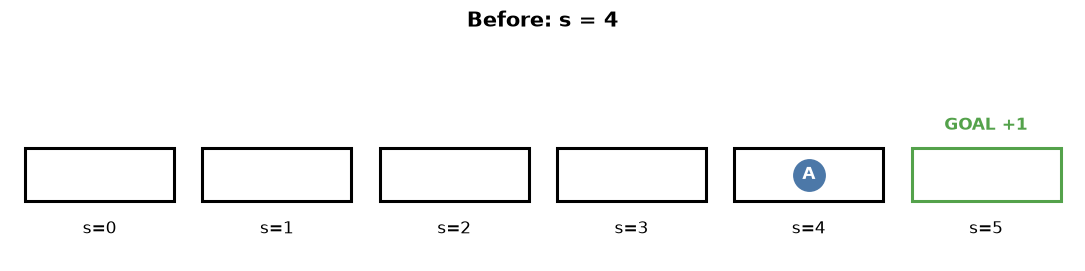

In [2]:
env=LineWorld(); env.reset(); env.position=4
fig=lineworld(4,title="Before: s = 4")
plt.show()

<div style="border-left:10px solid #F58518;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#F58518">ACTION</div><div style="font-size:21px;font-weight:800;margin-top:4px">a = 1</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Action ID 1 means RIGHT because the environment/action convention says so. It does not intrinsically mean “one step.”</div></div>

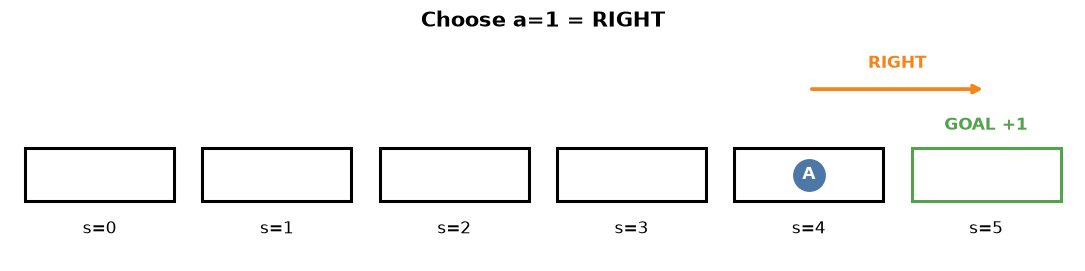

In [3]:
action=1
fig=lineworld(4,title="Choose a=1 = RIGHT",arrow=(4,5,"RIGHT"))
plt.show()

Now call `env.step(action)`. Read it as: **Environment, apply my action and report the result.**

5 1.0 True False {'old_position': 4}


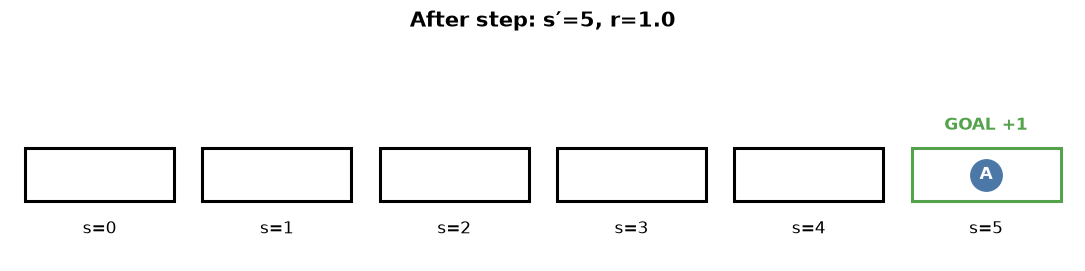

In [4]:
next_obs,reward,terminated,truncated,info=env.step(action)
print(next_obs,reward,terminated,truncated,info)
fig=lineworld(next_obs,title=f"After step: s′={next_obs}, r={reward}")
plt.show()

<div style="border-left:10px solid #5B8FF9;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#5B8FF9">S PRIME</div><div style="font-size:21px;font-weight:800;margin-top:4px">s′ is the next state</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Here s=4 and RIGHT leads to s′=5. s′ is not the actor; it is the world state after the transition.</div></div>

<div style="border-left:10px solid #72B7B2;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#72B7B2">OBSERVATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">Why `next_obs` instead of `s_prime`?</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Gym returns an observation. In LineWorld the world is fully observable, so observation = true state. Therefore `next_obs == s′`. In a POMDP they can differ.</div></div>

<div style="border-left:10px solid #54A24B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#54A24B">REWARD</div><div style="font-size:21px;font-weight:800;margin-top:4px">Reward r</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Immediate numeric feedback from the transition. It does not cause movement; the environment transition caused movement.</div></div>

<div style="border-left:10px solid #6B7280;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#6B7280">TERMINATED</div><div style="font-size:21px;font-weight:800;margin-top:4px">Natural task ending</div><div style="font-size:15px;line-height:1.55;margin-top:8px">`terminated=True` because reaching state 5 is defined by the environment as goal completion.</div></div>

<div style="border-left:10px solid #9CA3AF;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#9CA3AF">TRUNCATED</div><div style="font-size:21px;font-weight:800;margin-top:4px">Artificial cutoff</div><div style="font-size:15px;line-height:1.55;margin-top:8px">A time/step limit can end the episode even if the goal was not reached. That is truncation.</div></div>

<div style="border-left:10px solid #64748B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#64748B">INFO</div><div style="font-size:21px;font-weight:800;margin-top:4px">What is `_`?</div><div style="font-size:15px;line-height:1.55;margin-top:8px">The fifth return value is usually `info`, extra metadata. Writing `_` is Python convention for “I intentionally ignore this value.” It is not a counter.</div></div>

,t,s,a,s_prime,r,terminated,truncated
0,0,0,0,0,-0.02,False,False
1,1,0,0,0,-0.02,False,True


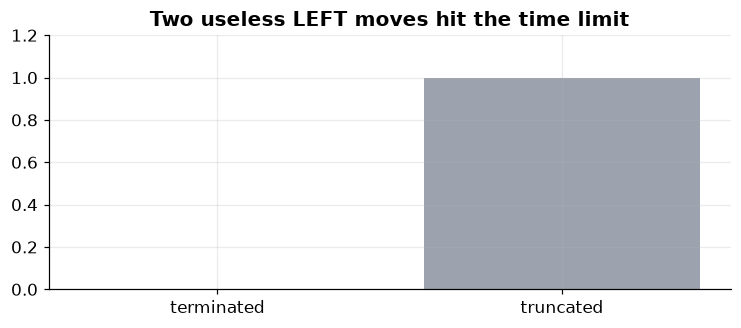

In [5]:
env=LineWorld(max_steps=2); obs,_=env.reset(); rows=[]
for t in range(2):
    n,r,term,trunc,info=env.step(0); rows.append([t,obs,0,n,r,term,trunc]); obs=n
df=pd.DataFrame(rows,columns=["t","s","a","s_prime","r","terminated","truncated"]); display(df)
plt.figure(figsize=(8,3)); plt.bar(["terminated","truncated"],[df.iloc[-1].terminated,df.iloc[-1].truncated],color=[COLORS["TERMINATED"],COLORS["TRUNCATED"]]); plt.ylim(0,1.2); plt.title("Two useless LEFT moves hit the time limit") ; plt.show()

Your **Apply button** analogy is right: action = press Apply; transition = backend/UI logic; s′ = resulting world; observation = what the agent can see afterward.